In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

current = Path.cwd().resolve()

PROJECT_ROOT = next(
    p for p in [current, *current.parents]
    if (p / "src" / "lithology").is_dir()
)

sys.path.insert(0, str(PROJECT_ROOT))

sns.set_theme(style="whitegrid")

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "weeks1_10_processed.csv"

df = pd.read_csv(DATA_PATH)

df.shape

(8590, 14)

In [2]:
df.head()

,DEPTH,GR,RHOB,DPOR,CNPOR,RILD,RILM,SP,PE,IGR,Vsh_Tertiary,Vsh_PreTertiary,Lithology,Lith_Label
0,2.0,138.1998,1.2619,84.6817,-5.9635,100000.0000,4.6520,229.0952,28.7214,1.000000,0.995671,0.990000,Shale,3
1,2.5,104.1713,1.3937,76.9745,-6.2541,100000.0000,3.1134,208.5166,27.5726,0.938652,0.838635,0.882380,Shale,3
2,3.0,81.3143,1.5491,67.8863,-6.4324,100000.0000,3.4019,170.1053,24.6974,0.648694,0.355128,0.481086,Sandy Shale,2
3,3.5,69.6746,1.7119,58.3702,-6.3958,100000.0000,2.3832,117.1226,20.1540,0.501036,0.217011,0.330949,Silty Sand,1
4,4.0,63.5526,1.8429,50.7058,-6.0216,13.5525,3.0790,59.6853,15.2962,0.423374,0.162831,0.263486,Silty Sand,1


In [3]:
df['Lithology'].value_counts()

Lithology
Clean Sand     3154
Silty Sand     2345
Sandy Shale    1678
Shale          1413
Name: count, dtype: int64

In [4]:
from src.lithology.models.trainer import LithologyTrainer

trainer = LithologyTrainer(
    df,
    PROJECT_ROOT / "outputs"
)

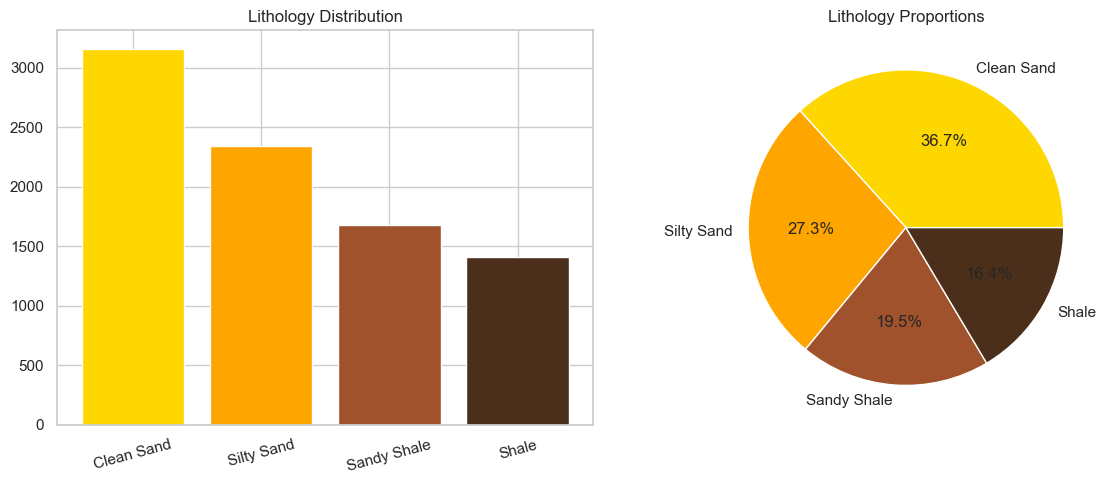

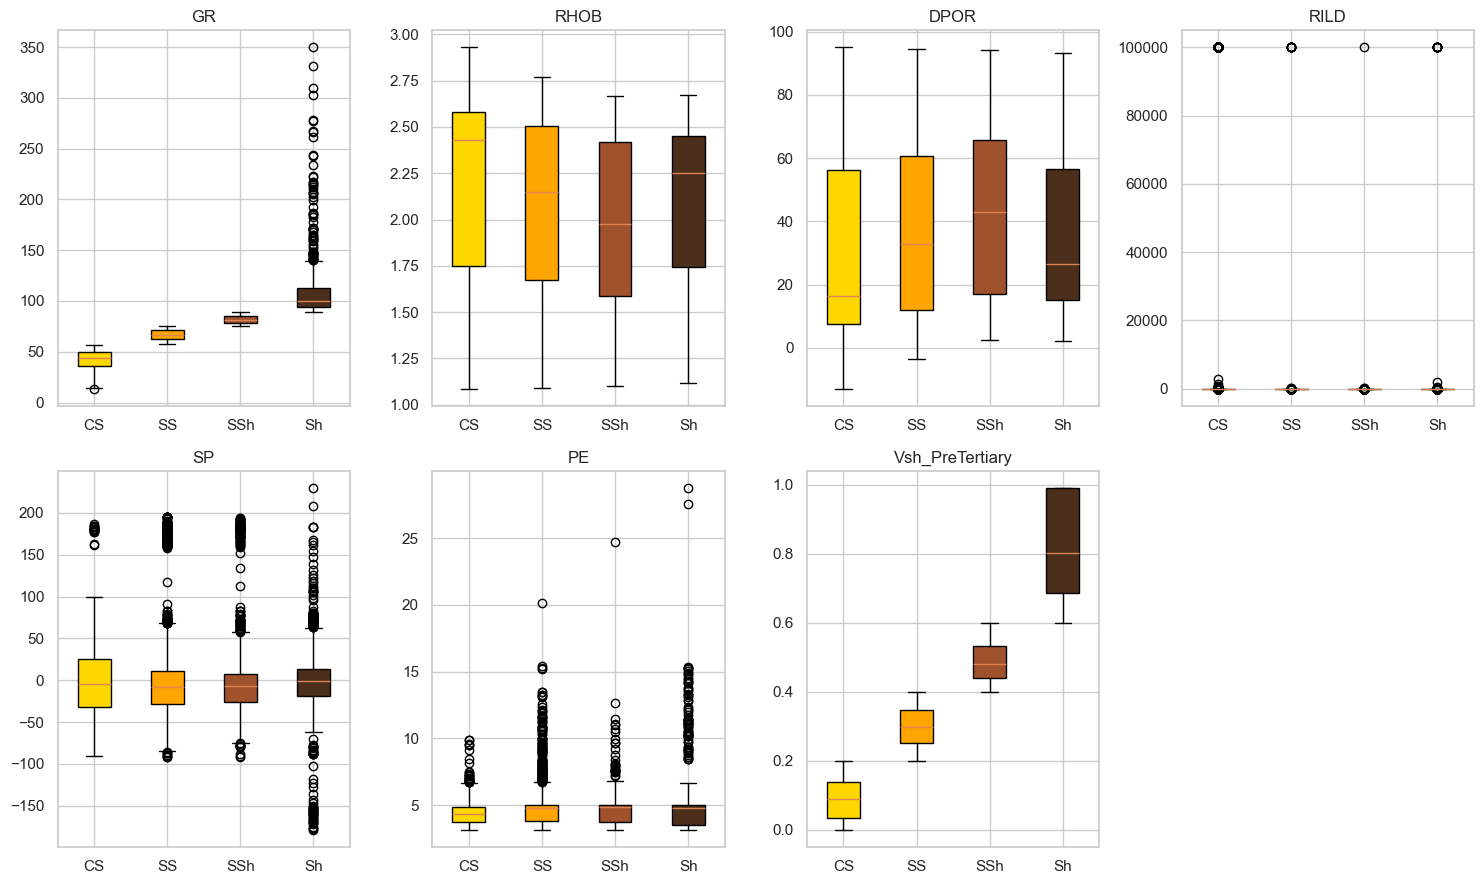

In [5]:
trainer.explore()

In [6]:
trainer.prepare_data()

In [7]:
trainer.X_train.shape, trainer.X_test.shape

((6872, 7), (1718, 7))

In [8]:
trainer.X_bal.shape

(10092, 7)

In [9]:
trainer.train()